# CatBoost e sobrevivência com filtro contextual

Resultado registrado: **613 atrasos sinalizados, 6,774 falsos alertas e 91 atrasos perdidos**, em 19.258 pedidos reais, dos quais 704 atrasaram.

Este arquivo reúne a preparação da entrada, o funcionamento das duas etapas, o cálculo do histórico e a conferência do resultado. A execução padrão carrega os pesos selecionados. O reajuste do filtro é opcional e permanece desativado.

## 1. Ambiente e arquivos

Selecione o Python da `.venv` do projeto como kernel. Os arquivos de `artefatos`, `dados` e `codigo` devem permanecer junto deste notebook. As versões utilizadas estão em `requirements.txt`. As dependências são carregadas antes da leitura dos pesos.

In [1]:
# Limita o uso de CPU nos cálculos numéricos.
import os
for variavel in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:
    os.environ[variavel]='4'
from pathlib import Path
import sys,json,copy
NOME_MODELO='Modelo_613_atrasos_6774_falsos_alertas_91_perdidos'
REFERENCIA='modelo_614'
RETENCAO=0.95
ESPERADO={'TP':613,'FP':6774,'FN':91}

# Localiza a pasta tanto a partir do notebook quanto da raiz do projeto.
PASTA=None
for origem in [Path.cwd(),*Path.cwd().parents]:
    for candidata in [origem,origem/'ML/modelos_finais']:
        if (candidata/'artefatos'/f'{NOME_MODELO}.joblib').is_file():
            PASTA=candidata.resolve()
            break
    if PASTA is not None:
        break
if PASTA is None:
    raise FileNotFoundError('Mantenha as pastas de apoio junto do notebook em ML/modelos_finais.')
CODIGO=PASTA/'codigo'
sys.path.insert(0,str(CODIGO))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import confusion_matrix,precision_score,recall_score,accuracy_score,ConfusionMatrixDisplay
import context_risk,logipredict_final
from logipredict_final.features import feature_frame
from context_risk.runtime import meta_frame
from operacao import carregar_modelo,carregar_avaliacao,prever_pedido,COLUNAS_ENTRADA

# Os módulos locais acompanham os pesos e mantêm a transformação utilizada no treino.
if not all(Path(p.__file__).resolve().is_relative_to(CODIGO) for p in [context_risk,logipredict_final]):
    raise RuntimeError('Reinicie o kernel para carregar os módulos locais desta pasta.')
print('Pasta dos arquivos:',PASTA)

Pasta dos arquivos: D:\Documentos\FACULDADE\5 semestre\LogiPredictAI\ML\modelos_finais


## 2. Carregamento dos pesos

O arquivo de pesos contém o detector inicial, o CatBoost revisor e o histórico real de entregas. O manifesto de integridade confere se os pesos e os metadados correspondem aos arquivos selecionados.

Os dois limites têm funções distintas: o primeiro seleciona os alertas do detector; o segundo decide quais alertas o filtro mantém. O score do filtro não é uma probabilidade populacional calibrada.

In [2]:
# O carregamento lê os pesos existentes; o reajuste fica no bloco opcional.
pacote=carregar_modelo(PASTA,NOME_MODELO)
modelo=pacote['pipeline']
metadados=pacote['metadata']
limiar_detector=float(modelo.reference_threshold)
limiar_filtro=float(modelo.threshold)
display(pd.Series({'Detector':type(modelo.reference).__name__,
    'Revisor':type(modelo.reviewer.model).__name__,
    'Árvores do revisor':modelo.reviewer.model.get_params()['iterations'],
    'Profundidade do revisor':modelo.reviewer.model.get_params()['depth'],
    'Limiar do detector':limiar_detector,'Limiar do filtro':limiar_filtro}))

Detector                    CandidatePipeline
Revisor                    CatBoostClassifier
Árvores do revisor                        350
Profundidade do revisor                     6
Limiar do detector                      0.019
Limiar do filtro                     0.049393
dtype: object

## 3. Arquitetura do classificador

A primeira etapa combina CatBoost e um modelo de sobrevivência AFT do XGBoost. O AFT estima a possibilidade de a duração da entrega ultrapassar o prazo. Os scores calibrados dos dois componentes são combinados com pesos iguais. Um segundo CatBoost, com 350 árvores e profundidade 6, revisa os alertas com o histórico contextual. A retenção de 95% na calibração define o filtro que sinalizou 613 atrasos nesta avaliação.

O filtro recebe o score do detector, as relações de peso/volume/preço/frete/prazo e o histórico por vendedor e rota. Ele pode retirar alertas, mas não recuperar pedidos descartados pela primeira etapa. As medianas e os codificadores do detector foram aprendidos no seu próprio conjunto de ajuste.

## 4. Entrada da avaliação

O arquivo de avaliação reúne pedidos reais da Olist. `atraso_real` é o resultado observado e serve apenas para conferir acertos e erros. Essa coluna fica separada das entradas do modelo.

As medidas usam gramas, centímetros cúbicos, quilômetros e reais. Datas são locais, sem fuso. Os prefixos CEP têm cinco dígitos e preservam zeros à esquerda. A previsão representa o instante do despacho.

In [3]:
# A leitura confere a integridade e preserva a precisão das medidas.
pedidos=carregar_avaliacao(PASTA)
entradas=pedidos[COLUNAS_ENTRADA].copy()
rotulos=pedidos['atraso_real'].astype(int).to_numpy()
assert 'atraso_real' not in entradas.columns
assert len(pedidos)==19258 and int(rotulos.sum())==704
display(entradas[['purchase_at','dispatched_at','seller_state','customer_state',
    'total_weight_g','distance_km','origin_prefix5','destination_prefix5']].head(3))
print('Pedidos:',len(pedidos),'| Atrasos reais:',int(rotulos.sum()))

,purchase_at,dispatched_at,seller_state,customer_state,total_weight_g,distance_km,origin_prefix5,destination_prefix5
0,2018-05-28 14:18:26,2018-05-29 12:04:00,SP,RJ,17850.0,371.903073,03111,25615
1,2018-05-27 22:21:55,2018-05-29 12:04:00,MG,SP,6050.0,294.031582,37175,03755
2,2018-05-29 00:19:06,2018-05-29 12:09:00,SP,SP,550.0,298.315502,14940,02273


Pedidos: 19258 | Atrasos reais: 704


## 5. Reajuste opcional do filtro

Este bloco é separado da execução padrão. A primeira etapa permanece com os pesos selecionados. O reajuste utiliza os seis CSVs reais, previsões temporais dos detectores e rótulos já disponíveis na data do ajuste.

O treino do filtro exclui despachos dos últimos 35 dias. A calibração utiliza o bloco entre 35 e 14 dias antes do ajuste, mantendo apenas rótulos já conhecidos. Os históricos são calculados com entregas anteriores ao despacho de cada pedido. A imputação e as estatísticas do teste não entram no ajuste.

Para refazer apenas o filtro, altere `REAJUSTAR_FILTRO` para `True`. Os CSVs completos precisam estar no projeto ou em `OLIST_DATASET_PATH`. O código não sobrescreve o arquivo original de pesos.

In [4]:
# Com o reajuste desativado, a avaliação usa o filtro já treinado.
REAJUSTAR_FILTRO=False
if REAJUSTAR_FILTRO:
    from treino import preparar_treino,reajustar_filtro
    dados_treino=preparar_treino(PASTA)
    modelo,informacoes_ajuste=reajustar_filtro(modelo,metadados,dados_treino,REFERENCIA,RETENCAO)
    limiar_detector=float(modelo.reference_threshold)
    limiar_filtro=float(modelo.threshold)
    display(pd.Series(informacoes_ajuste))
else:
    print('Execução com os pesos selecionados; nenhum treinamento foi iniciado.')

Execução com os pesos selecionados; nenhum treinamento foi iniciado.


## 6. Atributos e primeira etapa

Calculamos o tempo entre compra e despacho, os dias restantes até a promessa, o mês da compra e o dia da semana do despacho. Esses dados complementam as medidas, os valores e as UFs. O resultado real da entrega não participa dessa transformação.

In [5]:
# A transformação usa as mesmas colunas e a mesma ordem do detector treinado.
atributos_detector=feature_frame(entradas)
score_detector=modelo.reference.predict_proba(atributos_detector)[:,1]
passou_detector=score_detector>=limiar_detector
assert np.isfinite(score_detector).all()
print('Pedidos sinalizados pela primeira etapa:',int(passou_detector.sum()))
display(atributos_detector.head(3))

Pedidos sinalizados pela primeira etapa: 7543


,distance_km,total_weight_g,total_volume_cm3,items_count,sellers_count,price,freight_value,dispatch_lead_days,remaining_days,purchase_month,dispatch_weekday,seller_state,customer_state
0,371.903073,17850.0,84942.0,3,1,840.0,84.12,0.906644,31,5,1,SP,RJ
1,294.031582,6050.0,8000.0,1,1,110.0,29.49,1.570891,36,5,1,MG,SP
2,298.315502,550.0,25000.0,1,1,38.9,12.79,0.492986,44,5,1,SP,SP


## 7. Histórico disponível no despacho

A consulta considera somente entregas concluídas **antes** do despacho analisado. Eventos exatamente na hora da previsão também ficam de fora. O pedido atual não fornece seu próprio desfecho ao histórico.

As estatísticas cobrem histórico global, vendedor principal, par de UFs, rota por prefixos e destino. Janelas de 30 e 90 dias fornecem contagens, frequências de atraso, médias e P50/P90 de duração. A diferença entre o prazo disponível e essas durações mede a folga do pedido. Grupos pequenos têm suas taxas suavizadas em direção ao histórico global anterior.

Na avaliação, o histórico recebe entregas anteriores que já ocorreram durante o período. Os pesos não são reajustados com esses eventos.

In [6]:
# A função aplica a restrição temporal em cada linha consultada.
contexto=modelo.history.query(entradas)
display(contexto[['h_seller_count90','h_seller_late_rate90',
    'h_route_p50_90','h_route_p90_90','h_route_slack_p90_90']].head(5))

# Confere a contagem global no instante do primeiro pedido.
instante_exemplo=pd.Timestamp(entradas.dispatched_at.iloc[0])
entregas_anteriores=modelo.history.events.delivered_at.lt(instante_exemplo)
assert contexto.h_global_count.iloc[0]==int(entregas_anteriores.sum())
print('Entregas disponíveis no primeiro despacho:',int(entregas_anteriores.sum()))

,h_seller_count90,h_seller_late_rate90,h_route_p50_90,h_route_p90_90,h_route_slack_p90_90
0,9.0,0.083813,13.0,38.0,-7.0
1,181.0,0.086719,6.0,14.4,21.6
2,6.0,0.170402,3.0,11.0,33.0
3,392.0,0.151530,3.0,11.0,11.0
4,392.0,0.151530,3.0,11.0,11.0


Entregas disponíveis no primeiro despacho: 75205


## 8. Filtro contextual e decisão final

O CatBoost revisor avalia os atributos do pedido, o score do detector e o contexto. Um pedido só recebe alerta final se passar pelas duas etapas. Quando o detector já sinalizou um pedido com prazo vencido no despacho, o filtro conserva esse alerta.

In [7]:
# Aplica o revisor aos atributos do pedido e ao contexto histórico.
atributos_filtro=meta_frame(entradas,score_detector,limiar_detector,contexto)
score_revisor=modelo.reviewer.predict_proba(atributos_filtro)[:,1]

# Pedidos descartados pela primeira etapa continuam sem alerta.
score_final=np.where(passou_detector,score_revisor,0.)
dias_restantes=(entradas.estimated_delivery_at.dt.normalize()-entradas.dispatched_at.dt.normalize()).dt.days.to_numpy()
prazo_vencido=dias_restantes<0
score_final=np.where(prazo_vencido&passou_detector,1.,score_final)
alertas=score_final>=limiar_filtro
assert (alertas<=passou_detector).all()

# Confere se as duas etapas reproduzem a previsão do modelo carregado.
amostra=entradas.sample(12,random_state=42)
posicoes=entradas.index.get_indexer(amostra.index)
np.testing.assert_allclose(modelo.predict_proba(amostra)[:,1],score_final[posicoes],rtol=1e-8,atol=1e-10)
print('Pedidos com alerta final:',int(alertas.sum()))

Pedidos com alerta final: 7387


## 9. Conferência dos resultados

TP é atraso sinalizado; FP é pedido pontual que recebeu alarme; FN é atraso perdido. Precisão mede a proporção de alarmes verdadeiros e recall mede a proporção dos atrasos encontrados. Acurácia mede todos os acertos, inclusive os pedidos pontuais.

Os acertos de pedidos cujo prazo já venceu no despacho são separados das antecipações. Reconhecer um atraso já ocorrido não equivale a prevê-lo.

Atrasos sinalizados               613.000000
Falsos alertas                   6774.000000
Atrasos perdidos                   91.000000
Entregas pontuais sem alerta    11780.000000
Precisão                            0.082984
Recall                              0.870739
Acurácia                            0.643525
Name: Avaliação registrada, dtype: float64

Atrasos antecipados               481
Prazos já vencidos sinalizados    132
dtype: int64

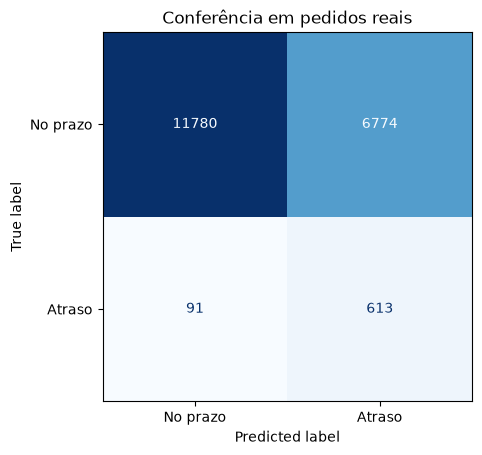

In [8]:
matriz=confusion_matrix(rotulos,alertas,labels=[0,1])
tn,fp,fn,tp=matriz.ravel()
contagem={'TP':int(tp),'FP':int(fp),'FN':int(fn)}
assert contagem==ESPERADO,contagem
medidas={'Atrasos sinalizados':int(tp),'Falsos alertas':int(fp),'Atrasos perdidos':int(fn),
    'Entregas pontuais sem alerta':int(tn),'Precisão':precision_score(rotulos,alertas),
    'Recall':recall_score(rotulos,alertas),'Acurácia':accuracy_score(rotulos,alertas)}
display(pd.Series(medidas,name='Avaliação registrada'))
display(pd.Series({'Atrasos antecipados':int((alertas&(rotulos==1)&~prazo_vencido).sum()),
    'Prazos já vencidos sinalizados':int((alertas&(rotulos==1)&prazo_vencido).sum())}))
ConfusionMatrixDisplay(matriz,display_labels=['No prazo','Atraso']).plot(cmap='Blues',values_format='d',colorbar=False)
plt.title('Conferência em pedidos reais')
plt.show()

## 10. Consulta de um pedido

O exemplo usa somente os campos disponíveis no despacho. O identificador do vendedor e os prefixos devem corresponder a dados reais para consultar o histórico. O validador rejeita campos de desfecho, como `is_late` e `delivered_at`. O retorno é um score e uma decisão de risco; não é garantia sobre a entrega.

In [9]:
# Seleciona um pedido com alerta para demonstrar a mesma decisão individual.
posicao=int(np.flatnonzero(alertas)[0])
pedido_exemplo=entradas.iloc[posicao].to_dict()
resultado=prever_pedido(modelo,pedido_exemplo)
display(pd.Series(resultado))
np.testing.assert_allclose(resultado['score'],score_final[posicao],rtol=1e-8,atol=1e-10)
assert resultado['risco_sinalizado']==bool(alertas[posicao])

score                    1.0
limiar              0.049393
risco_sinalizado        True
dtype: object

## 11. Uso e limites

Os arquivos de pesos e os módulos de `codigo` permitem carregar o classificador sem refazer o treino. Para uso no serviço final, o pedido precisa fornecer as identidades de vendedor e CEP, e o histórico de entregas precisa ser mantido atualizado. O frame antigo de somente 13 atributos não contém todas essas informações.

Os dados Olist são de 2016–2018 e a avaliação contém pedidos posteriormente entregues que passaram nos filtros de qualidade. O período final já foi examinado nas pesquisas; os resultados são retrospectivos e precisam de confirmação em um período novo antes de uso operacional. Nenhum modelo é ativado na aplicação pela execução deste notebook.